In [2]:

%cd ..

from pathlib import Path
print(Path.cwd())

import numpy as np
import matplotlib.pyplot as plt

from hardware import ammeter, ammeter_uncertainty, gaussmeter, gaussmeter_uncertainty, horizontal_coils, vertical_coils, modulation_coils, horizontal_coils_uncertainty, vertical_coils_uncertainty, modulation_coils_uncertainty

plt.rcParams.update({
    "font.sans-serif": ["Cabin", "Libertinus Sans", "DejaVu Sans"],
    "font.serif": ["Libertinus Serif"],
    "font.family": "sans-serif",
    "font.style": "normal",
    "font.weight": "normal",
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelweight": "normal",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
    "legend.title_fontsize": 14,
    "figure.titlesize": 18,
    "figure.titleweight": "bold",
    "mathtext.fontset": "cm",
    "mathtext.default": "it",
    "axes.unicode_minus": False,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.edgecolor": "black",
})
%matplotlib inline

from scipy.optimize import curve_fit
from scipy import signal


c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code
c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code


[-3.97272167e-09  5.57151818e-02  2.30833979e-01  7.67520767e-09
  8.14701638e-11]
Zero at 0.05572 +/- 0.00028 G


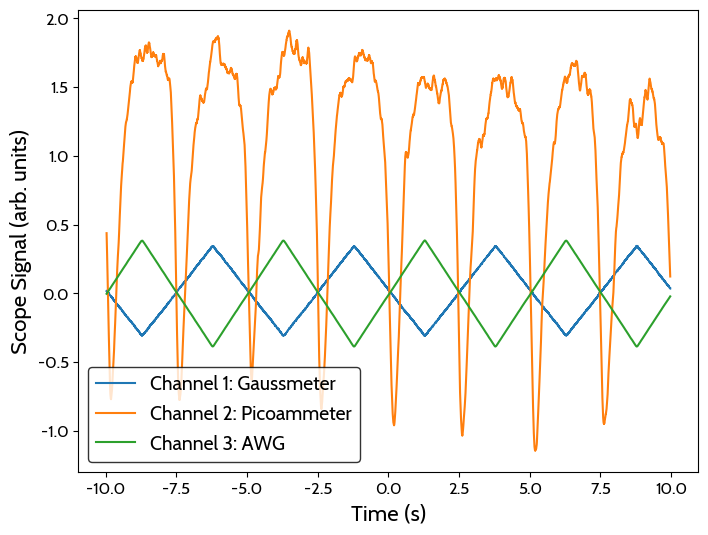

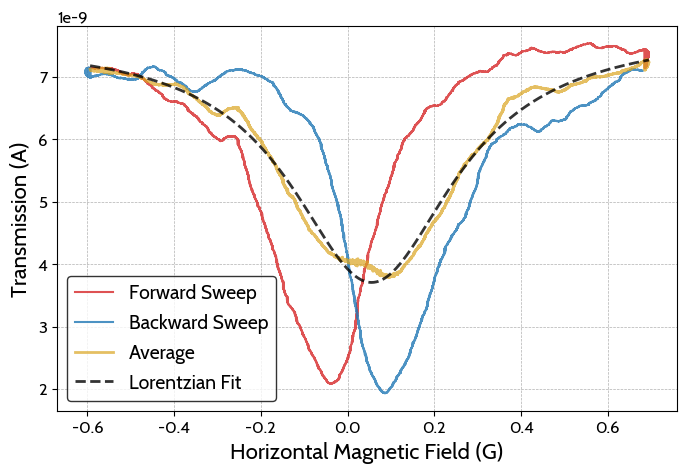

In [56]:
# horizontal field sweep (with vertical field zeroed)
t, V1, V2, V3 = np.loadtxt("data/17/scope_7.csv", delimiter=",", unpack=True, skiprows = 2)


N = 200
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

# forward
mask = (t > -1.25) & (t < 1.25)
transmission_forward = ammeter(V2[mask]*1e3)
transmission_forward_uncertainty = ammeter_uncertainty(V2[mask]*1e3)
field_forward = gaussmeter(V1[mask]*1e3)
field_forward_uncertainty = gaussmeter_uncertainty(V1[mask]*1e3)

#backward
mask = (t > 1.25) & (t < 1.25 + 2.5)
transmission_backward = ammeter(V2[mask]*1e3)
transmission_backward_uncertainty = ammeter_uncertainty(V2[mask]*1e3)
field_backward = gaussmeter(V1[mask]*1e3)
field_backward_uncertainty = gaussmeter_uncertainty(V1[mask]*1e3)

#combined
sort_indices = np.argsort(field_forward)
field_forward = field_forward[sort_indices]
transmission_forward = transmission_forward[sort_indices]
sort_indices = np.argsort(field_backward)
field_backward = field_backward[sort_indices]
transmission_backward = transmission_backward[sort_indices]

field = field_forward
transmission = np.mean([transmission_forward, transmission_backward[:-1]], axis=0)

#lorenzian fit:
def f(x, a, b, c, d, e):
    return a/(1 + ((x-b)/c)**2) + d + e*x
popt, pcov = curve_fit(f, field, transmission, p0=[-1e-9, 0, 10, 0.5, 0])
print(popt)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(field_forward, transmission_forward, label='Forward Sweep', color='tab:red', alpha = 0.8)
ax.plot(field_backward, transmission_backward, label='Backward Sweep', color='tab:blue', alpha = 0.8)

ax.plot(field, transmission, label='Average', lw = 2, color='goldenrod', alpha = 0.7)
ax.plot(field, f(field, *popt), label='Lorentzian Fit', lw = 2, ls = '--', color='k', alpha = 0.8)

ax.set_xlabel('Horizontal Magnetic Field (G)')
ax.set_ylabel('Transmission (A)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

print(f"Zero at {popt[1]:.5f} +/- {np.sqrt(pcov[1, 1]):.5f} G")

[ 3.25025242e-09  4.29301274e-02 -2.07852767e-01  2.33182452e-09
  8.93899244e-10]
Zero at 0.04293 +/- 0.00022 G


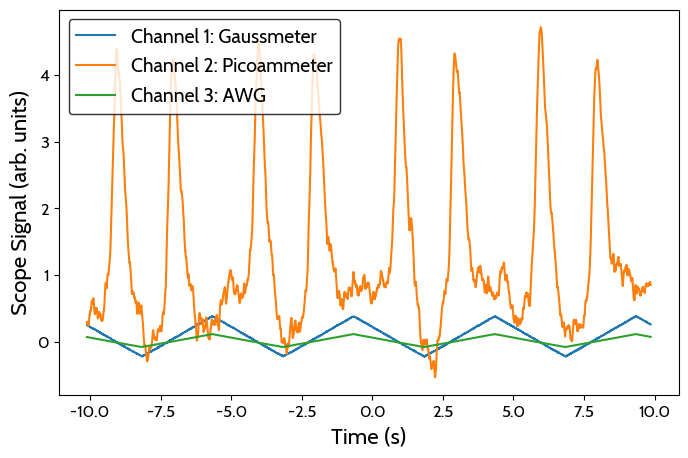

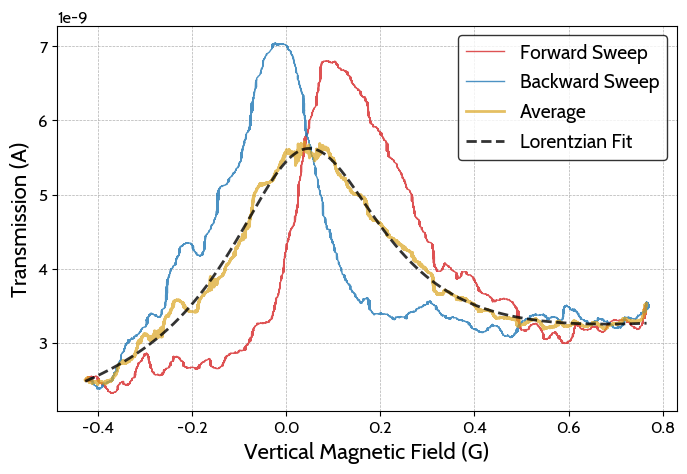

In [54]:
# vertical field sweep (with horizontal field zeroed)
t, V1, V2, V3 = np.loadtxt("data/17/scope_8.csv", delimiter=",", unpack=True, skiprows = 2)


N = 100
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 5))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*10-2.5, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

#forward
mask = (t > -3.17) & (t < -3.17+2.5)
field_forward = gaussmeter(V1[mask]*1e3)
transmission_forward = ammeter(V2[mask]*1e3)
#backward
mask = (t > -3.17+2.5) & (t < -3.17+2.5+2.5)
field_backward = gaussmeter(V1[mask]*1e3)
transmission_backward = ammeter(V2[mask]*1e3)

#combined
sort_indices = np.argsort(field_forward)
field_forward = field_forward[sort_indices]
transmission_forward = transmission_forward[sort_indices]
sort_indices = np.argsort(field_backward)
field_backward = field_backward[sort_indices]
transmission_backward = transmission_backward[sort_indices]

field = field_forward
transmission = np.mean([transmission_forward, transmission_backward], axis=0)

def f(x, a, b, c, d, e):
    return a/(1 + ((x-b)/c)**2) + d + e*x
popt, pcov = curve_fit(f, field, transmission, p0=[5e-9, 0.05, -.1, 3e-9, 0])
print(popt)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(field_forward, transmission_forward, lw = 1, label='Forward Sweep', color='tab:red', alpha = 0.8)
ax.plot(field_backward, transmission_backward, lw = 1, label='Backward Sweep', color='tab:blue', alpha = 0.8)
ax.plot(field, transmission, label='Average', lw = 2, color='goldenrod', alpha = 0.7)
ax.plot(field, f(field, *popt), label='Lorentzian Fit', lw = 2, ls = '--', color='k', alpha = 0.8)

ax.set_xlabel('Vertical Magnetic Field (G)')
ax.set_ylabel('Transmission (A)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

print(f"Zero at {popt[1]:.5f} +/- {np.sqrt(pcov[1, 1]):.5f} G")

[-3.52465576e-09 -1.45869465e-01  2.18738107e-01  1.71326009e-01
  9.33082072e-01 -5.38509901e-02  3.29264889e-01  1.43110269e+00
  1.53845181e-01  1.85504164e-09  2.88357912e-10]
Peak locations: -0.1459 +/- 0.0004 G, 0.9331 +/- 0.0012 G, 1.4311 +/- 0.0010 G
Peak heights: 0.1713 +/- 0.0035, 0.3293 +/- 0.0025


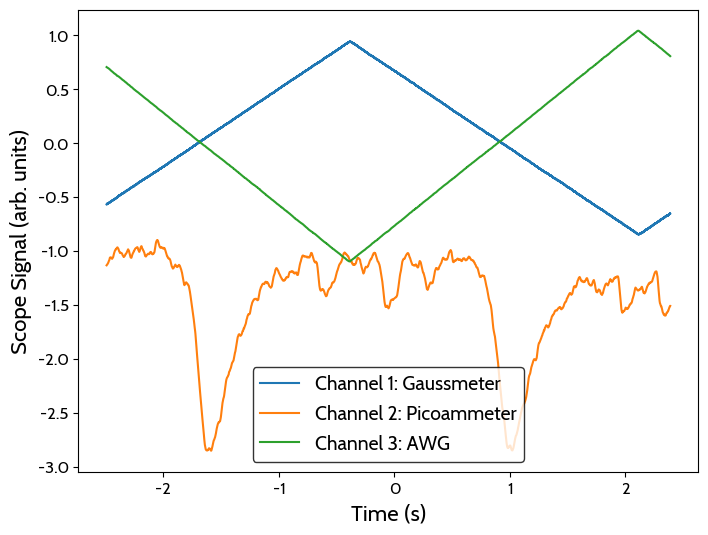

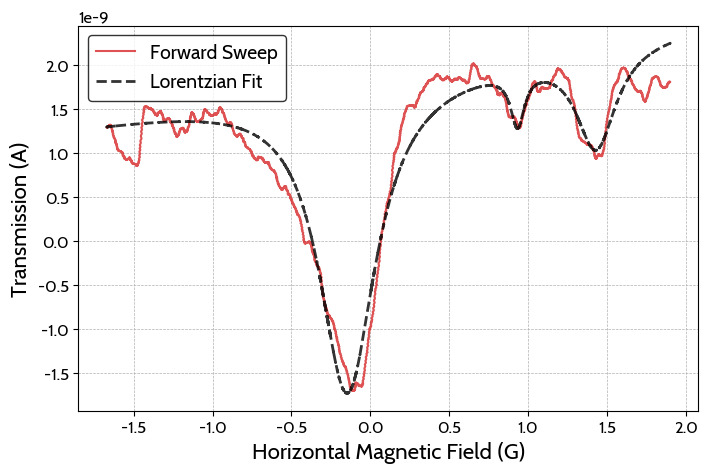

In [89]:
# horizontal field sweep with rf
t, V1, V2, V3 = np.loadtxt("data/17/scope_10.csv", delimiter=",", unpack=True, skiprows = 2)


N = 200
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

# forward
mask = (t > -.38) & (t < 2.1)
transmission_forward = ammeter(V2[mask]*1e3)
field_forward = gaussmeter(V1[mask]*1e3)

# fit to 3 lorenzians
def f(x, a1, b1, c1, a2, b2, c2, a3, b3, c3, d, e):
    return a1*(1/(1 + ((x-b1)/c1)**2) + 
            a2/(1 + ((x-b2)/c2)**2) + 
            a3/(1 + ((x-b3)/c3)**2)) + d + e*x
popt, pcov = curve_fit(f, field_forward[field_forward > -1], transmission_forward[field_forward > -1], p0=[
    -3e-9, 0, .1, 
    0.25, 0.95, .01, 
    0.25, 1.4, .01, 
    0.5, 0],
    bounds = ([-np.inf, -0.16, -np.inf, -np.inf, 0.85, -np.inf, -np.inf, 1.3, -np.inf, -np.inf, -np.inf], [np.inf, 0, np.inf, np.inf, 1, np.inf, np.inf, 1.5, np.inf, np.inf, np.inf]))
print(popt)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(field_forward, transmission_forward, label='Forward Sweep', color='tab:red', alpha = 0.8)
ax.plot(field_forward, f(field_forward, *popt), label='Lorentzian Fit', lw = 2, ls = '--', color='k', alpha = 0.8)

ax.set_xlabel('Horizontal Magnetic Field (G)')
ax.set_ylabel('Transmission (A)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

print(f"Peak locations: {popt[1]:.4f} +/- {np.sqrt(pcov[1, 1]):.4f} G, {popt[4]:.4f} +/- {np.sqrt(pcov[4, 4]):.4f} G, {popt[7]:.4f} +/- {np.sqrt(pcov[7, 7]):.4f} G")
print(f"Peak heights: {popt[3]:.4f} +/- {np.sqrt(pcov[3, 3]):.4f}, {popt[6]:.4f} +/- {np.sqrt(pcov[6, 6]):.4f}")

In [79]:
%matplotlib inline